# LeetCode #134: Gas Station

https://leetcode.com/problems/gas-station/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Brute Force | O(n²) | O(1) |
| Greedy ★ | O(n) | O(1) |

## Understanding the Methods
### Brute Force
Try each gas station as a starting point. Simulate the full circuit from that station, checking if we run out of gas. If we complete the full loop, return that index. O(n²) time.

### Optimal: Greedy ★
Key insight: If total gas >= total cost, a solution always exists. Track running tank sum. If it goes negative at index i, we can't start from any station 0..i — reset start to i+1 and reset tank. At the end, if total gas >= total cost, return the saved start index.

## Solutions
### C#

In [ ]:
// Greedy O(n) time, O(1) space
public class Solution {
    public int CanCompleteCircuit(int[] gas, int[] cost) {
        int totalGas = 0, totalCost = 0;
        int tank = 0, start = 0;
        for (int i = 0; i < gas.Length; i++) {
            totalGas += gas[i];
            totalCost += cost[i];
            tank += gas[i] - cost[i];
            if (tank < 0) {
                start = i + 1;
                tank = 0;
            }
        }
        return totalGas >= totalCost ? start : -1;
    }
}

### Python

In [ ]:
# Greedy O(n) time, O(1) space
class Solution:
    def canCompleteCircuit(self, gas: list[int], cost: list[int]) -> int:
        total_gas = total_cost = tank = start = 0
        for i in range(len(gas)):
            total_gas += gas[i]
            total_cost += cost[i]
            tank += gas[i] - cost[i]
            if tank < 0:
                start = i + 1
                tank = 0
        return start if total_gas >= total_cost else -1

### Go

In [ ]:
// Greedy O(n) time, O(1) space
func canCompleteCircuit(gas []int, cost []int) int {
    totalGas, totalCost, tank, start := 0, 0, 0, 0
    for i := range gas {
        totalGas += gas[i]
        totalCost += cost[i]
        tank += gas[i] - cost[i]
        if tank < 0 {
            start = i + 1
            tank = 0
        }
    }
    if totalGas >= totalCost {
        return start
    }
    return -1
}

### Rust

In [ ]:
// Greedy O(n) time, O(1) space
impl Solution {
    pub fn can_complete_circuit(gas: Vec<i32>, cost: Vec<i32>) -> i32 {
        let (mut total_gas, mut total_cost, mut tank, mut start) = (0i32, 0i32, 0i32, 0usize);
        for i in 0..gas.len() {
            total_gas += gas[i];
            total_cost += cost[i];
            tank += gas[i] - cost[i];
            if tank < 0 {
                start = i + 1;
                tank = 0;
            }
        }
        if total_gas >= total_cost { start as i32 } else { -1 }
    }
}

## Example Scenarios

### 1. Common Case — reset lands on the answer
**Input:** gas = [1,2,3,4,5], cost = [3,4,5,1,2]
Running `tank` goes negative through stations 0-2, so `start` is pushed to 3. From index 3 the diffs are $+3,+3$ and total gas $15 \ge$ total cost $15$, so the circuit closes. Answer **3**.

### 2. Slightly Complex — reset to last station
**Input:** gas = [2,3,4], cost = [3,4,2]
Diffs are $-1,-1,+2$. `tank` dips below 0 at stations 0 and 1, pushing `start` to 2. Total gas $9 \ge$ total cost $9$, so starting at 2 (where the big surplus is) completes the loop. Answer **2**.

### 3. Edge Case: Time Factor — single station
**Input:** gas = [5], cost = [4]
One station, diff $+1$. `tank` never goes negative and total gas $\ge$ total cost, so the lone station is a valid start. Answer **0**.

### 4. Edge Case: Space Factor — O(1) extra memory
**Input:** gas = [1,2], cost = [2,1]
Station 0 diff $-1$ sends `tank` negative, resetting `start` to 1. Station 1 diff $+1$. Totals balance ($3 \ge 3$). Only four scalars are tracked regardless of n. Answer **1**.

### 5. Almost-Impossible but Plausible — impossible circuit
**Input:** gas = [1,1], cost = [2,2]
Total gas $2 <$ total cost $4$, so no starting station can complete the loop. The final total check returns **-1**.


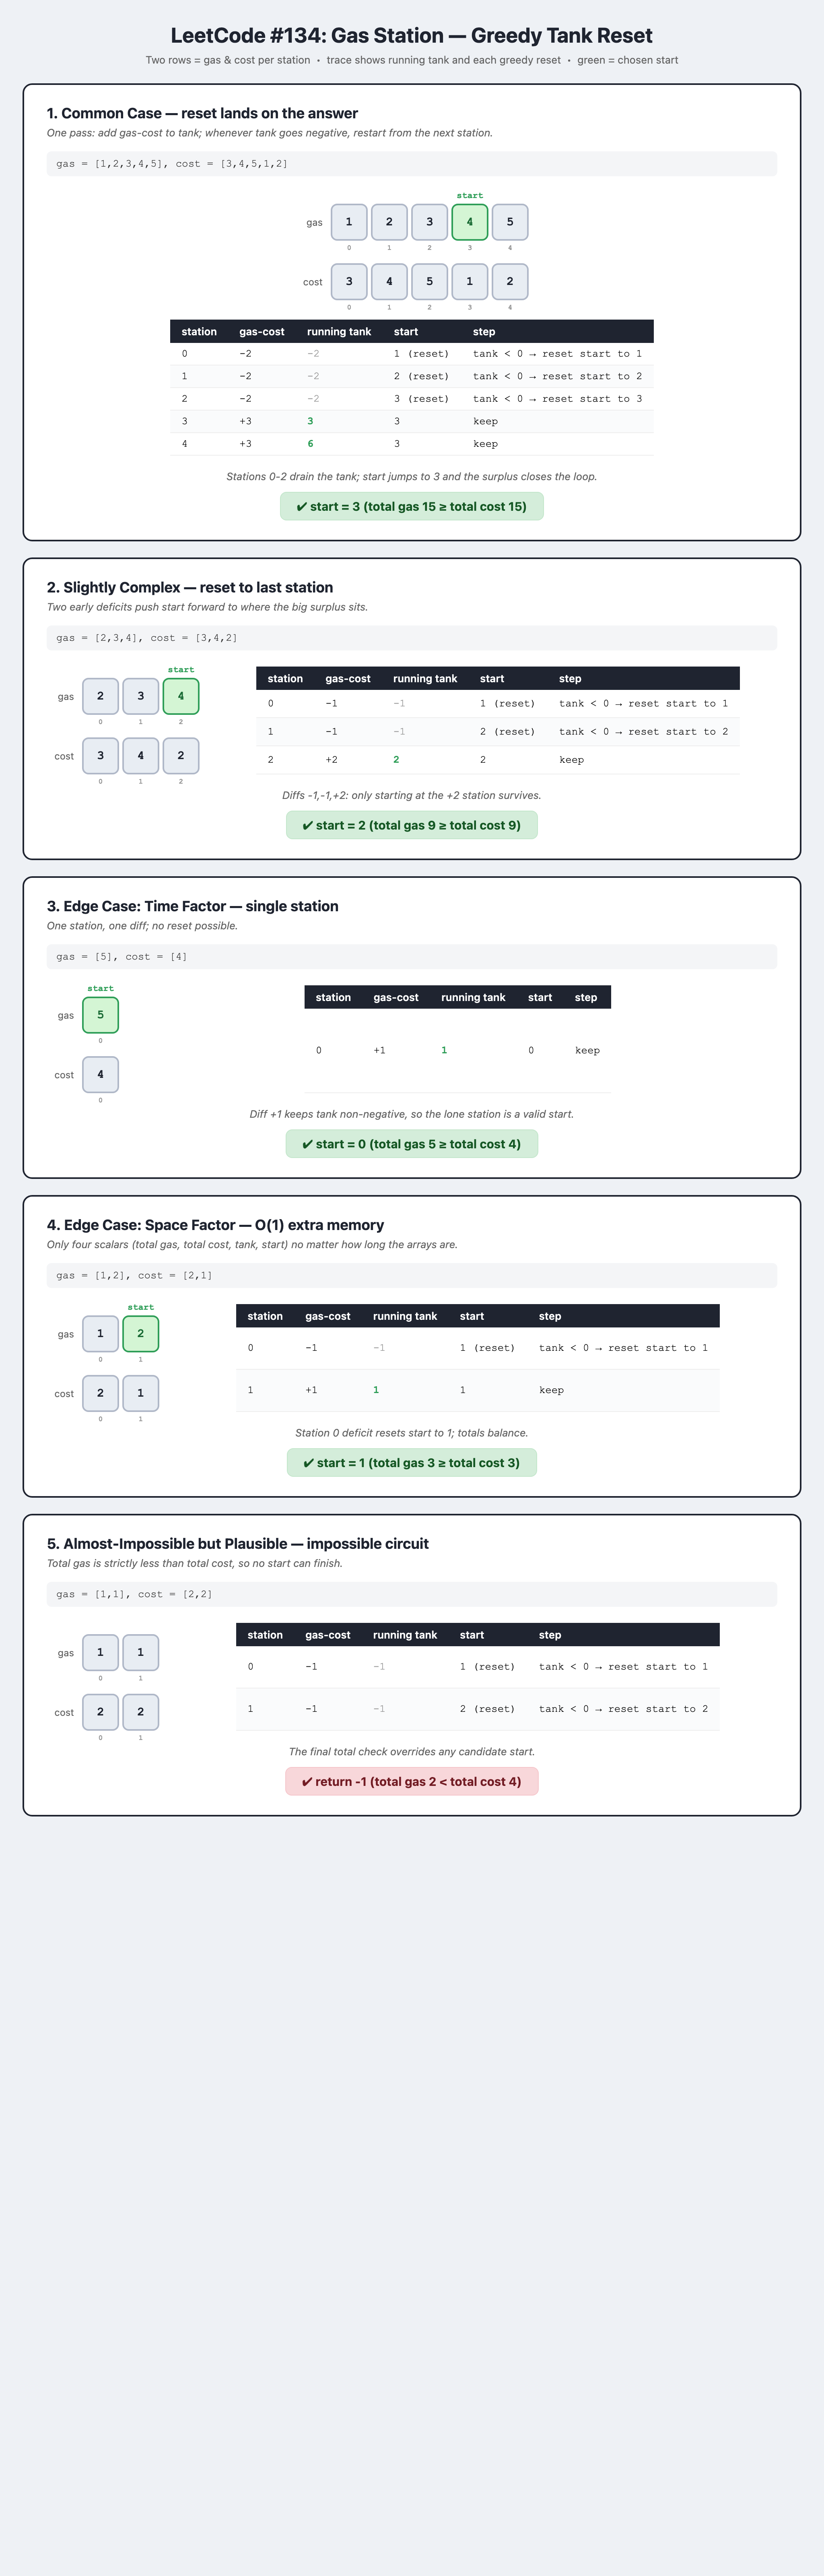